In [ ]:
import decoupler as dc
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import pandas as pd
from pydeseq2.dds import DeseqDataSet, DefaultInference
from pydeseq2.ds import DeseqStats
import scanpy as sc

/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
script_dir = Path.cwd()
project_dir = script_dir.parent
data_filepath = project_dir / "processed_data" / "uc_Epi_clustered.h5ad"

sc_adata = sc.read_h5ad(data_filepath)

In [8]:
sc_adata

AnnData object with n_obs × n_vars = 69313 × 2000
    obs: 'samples', 'Cluster', 'Subject', 'Health', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'cell_type_group', 'leiden'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'Cluster_colors', 'Health_colors', 'cell_type_group_colors', 'hvg', 'leiden', 'leiden_colors', 'leiden_nn10_pc10_res0.25', 'leiden_nn10_pc10_res0.5', 'leiden_nn10_pc10_res0.75', 'leiden_nn10_pc10_res1', 'leiden_nn10_pc10_res1.5', 'leiden_nn10_pc10_res2', 'leiden_nn10_pc15_res0.25', 'leiden_nn10_p

Relevant data in this object:

- obs: cell_type_group, leiden, Subject, Health

The goal of this DEA is to identify genes that differentiate disease state in each cell type. We will start by pseudobulking the broad cell type annotations (cell_type_group) and then mapping the expression of the top DE genes back to the tSNE space, and see how they are distributed across clusters (leiden).

The output pseudobulked adata object can be input to our prediction model. Count normalization should be integrated into prediction pipeline per model selected.

Number of pseudobulked cells: 917
Health
Healthy         336
Non-inflamed    315
Inflamed        266
Name: count, dtype: int64


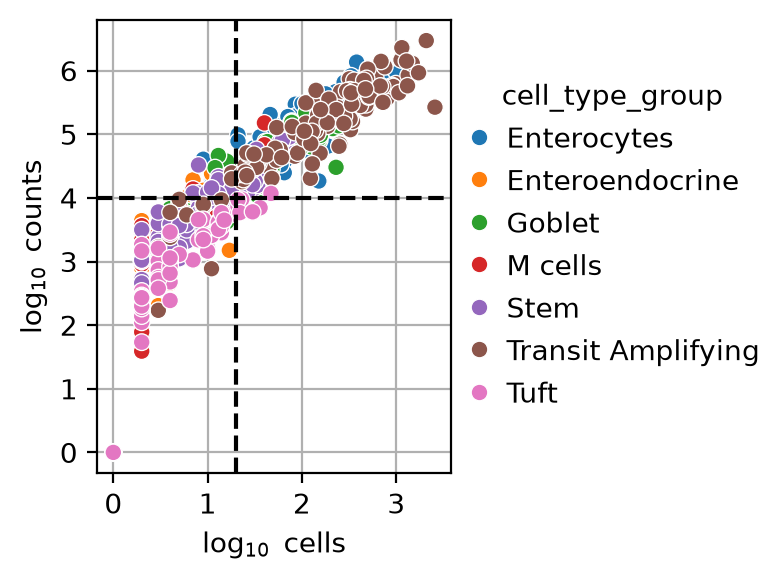

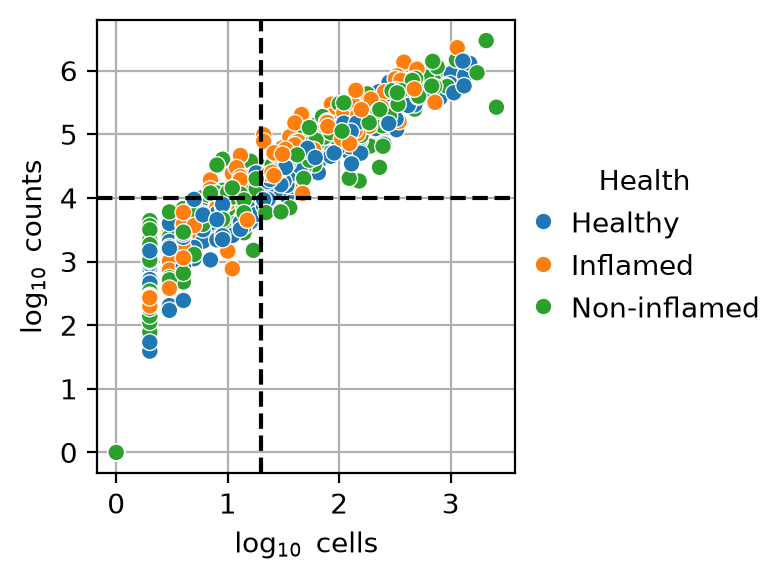

In [ ]:
# pseudobulk from the raw counts, not normalized ones
# new object will have one observation per cell type per sample, rather than individual observations per cell type per sample
pb_ct_adata = dc.pp.pseudobulk(adata=sc_adata, layer="counts", sample_col="samples", groups_col="cell_type_group", mode="sum")
print("Number of pseudobulked cells:", pb_ct_adata.shape[0])
print(pb_ct_adata.obs['Health'].value_counts())

dc.pl.filter_samples(pb_ct_adata, groupby=["cell_type_group"], min_cells=20, min_counts=10000)
dc.pl.filter_samples(pb_ct_adata, groupby=["Health"], min_cells=20, min_counts=10000)

In [ ]:
# filter out bulk samples that have too few cells or too few gene counts
dc.pp.filter_samples(pb_ct_adata, min_cells=20, min_counts=10000)
print("Number of pseudobulked cells after filtering:", pb_ct_adata.shape[0])
print(pb_ct_adata.obs['Health'].value_counts())

Number of pseudobulked cells after filtering: 292
Health
Non-inflamed    105
Healthy          98
Inflamed         89
Name: count, dtype: int64


In [ ]:
out_filepath = project_dir / "processed_data" / "cell_type_groups_pseudobulked_Epi_filtered.h5ad"
pb_ct_adata.write_h5ad(out_filepath, compression="gzip")

Number of pseudobulked cells: 1310
Health
Healthy         480
Non-inflamed    450
Inflamed        380
Name: count, dtype: int64
Number of pseudobulked cells after filtering: 437
Health
Non-inflamed    160
Healthy         154
Inflamed        123
Name: count, dtype: int64


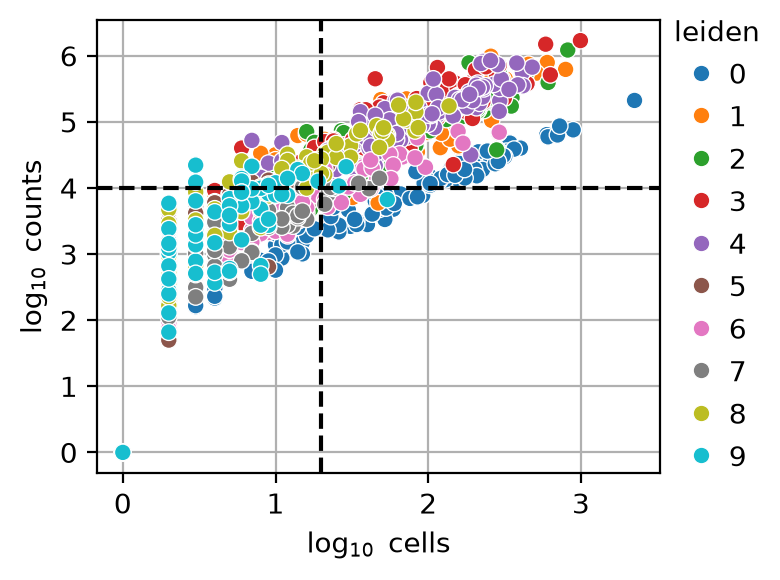

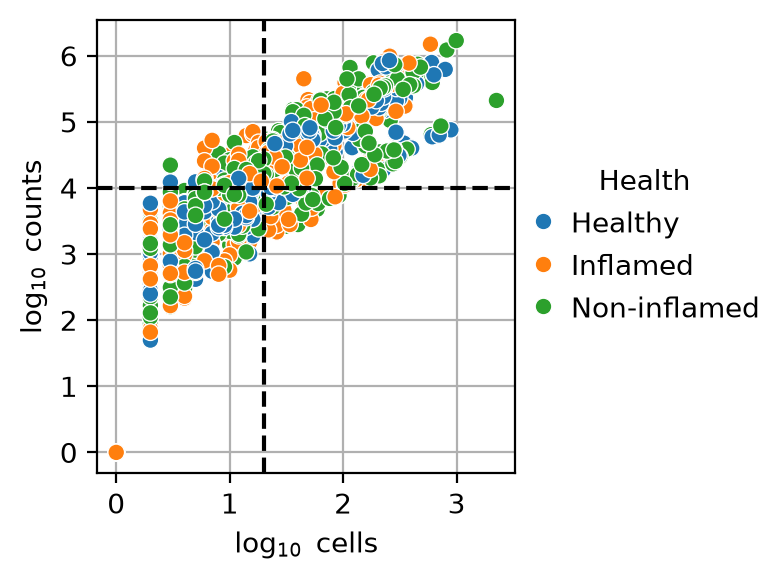

In [76]:
# Different pseudobulking, by cluster assignment rather than cell type group
pb_cl_adata = dc.pp.pseudobulk(adata=sc_adata, layer="counts", sample_col="samples", groups_col="leiden", mode="sum")
print("Number of pseudobulked cells:", pb_cl_adata.shape[0])
print(pb_cl_adata.obs['Health'].value_counts())

dc.pl.filter_samples(pb_cl_adata, groupby=["leiden"], min_cells=20, min_counts=10000)
dc.pl.filter_samples(pb_cl_adata, groupby=["Health"], min_cells=20, min_counts=10000)

dc.pp.filter_samples(pb_cl_adata, min_cells=20, min_counts=10000)
print("Number of pseudobulked cells after filtering:", pb_cl_adata.shape[0])
print(pb_cl_adata.obs['Health'].value_counts())

out_filepath = project_dir / "processed_data" / "leiden_cl_pseudobulked_Epi_filtered.h5ad"
pb_cl_adata.write_h5ad(out_filepath, compression="gzip")

DEA will require use of both pb_adata (for actual DEA) and sc_adata (for visualizing DE genes)

NOTE: DeseqStats use whatever condition comes alphabetically first as the baseline

In [78]:
def PseudobulkedDEA(dds, group, metadata_col, condition1, condition2):
    ''' 
    Runs DeseqStats on a DeseqDataSet object (which intended to contain metadata for only a single cell type).
    Returns the top 20 results sorted by padj, and prints a volcano plot
    '''
    inference = DefaultInference(n_cpus=8)

    stat_res = DeseqStats(dds, contrast=[metadata_col, condition1, condition2], inference=inference, quiet=True)
    stat_res.summary()
    results_df = stat_res.results_df
    sorted_results = results_df.sort_values(by="padj", ascending=True)
    print(sorted_results.head())

    dc.pl.volcano(results_df, x="log2FoldChange", y="padj")
    plt.title(group)
    plt.show()

    return sorted_results.head(20)


Conducting differential expression analysis in Enterocytes 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
           baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P    427.253326       -6.187213  0.301431 -20.526112  1.258510e-93  2.517020e-90
PLA2G2A  628.960881       -5.062690  0.366427 -13.816386  2.030094e-43  2.030094e-40
REG4     486.698257       -9.574067  0.813838 -11.764087  5.976917e-32  3.984611e-29
SPINK5   117.315157       -4.594869  0.397950 -11.546333  7.703753e-31  3.851876e-28
TFF1     727.814570       -5.472524  0.478607 -11.434267  2.819085e-30  1.127634e-27


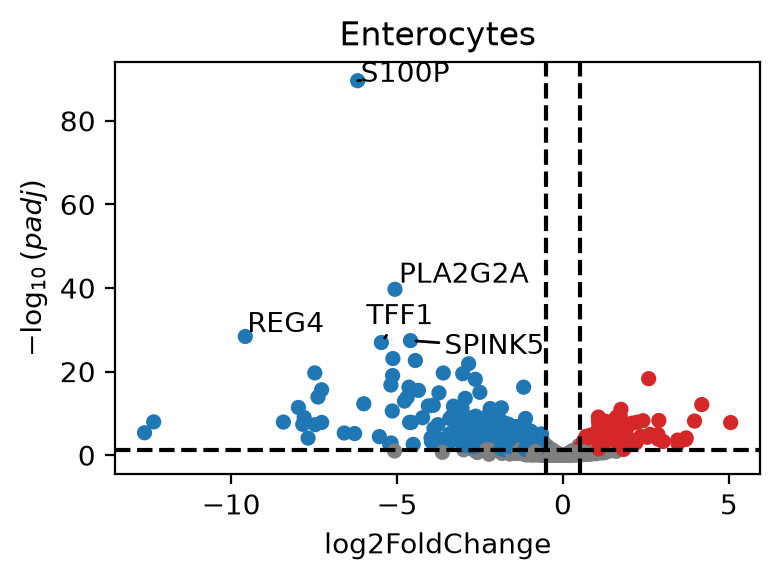

Second condition: healthy vs non-inflammed
            baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P     427.253326       -5.467764  0.288832 -18.930632  6.379273e-80  1.226096e-76
PLA2G2A   628.960881       -4.633762  0.349810 -13.246524  4.725905e-40  4.541595e-37
SPINK5    117.315157       -3.926134  0.381230 -10.298587  7.150402e-25  4.581024e-22
REG4      486.698257       -7.701359  0.779257  -9.882953  4.935654e-23  2.371582e-20
AGR2     1357.074720       -2.487264  0.262344  -9.480925  2.520386e-21  8.774791e-19


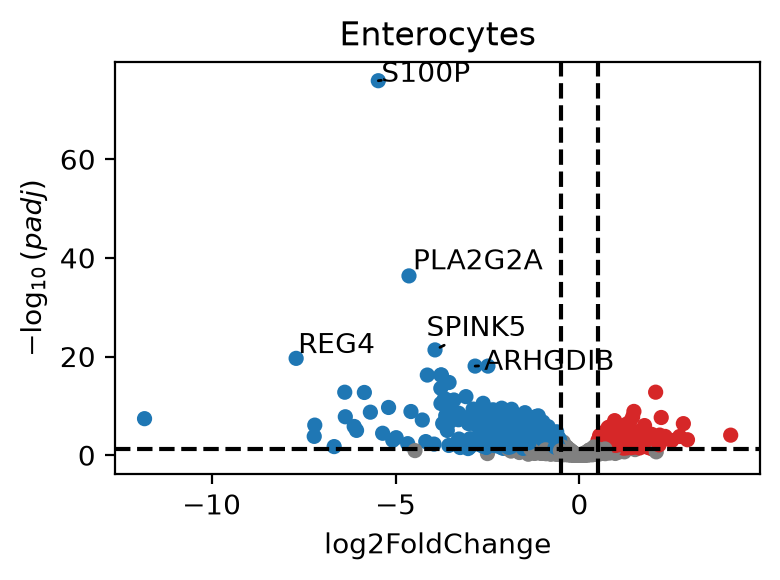

Third condition: inflammed vs non-inflammed
             baseMean  log2FoldChange     lfcSE      stat        pvalue      padj
C12orf75   115.211123        0.955155  0.169167  5.646230  1.640040e-08  0.000012
S100A6    7251.194020        0.566362  0.130567  4.337697  1.439837e-05  0.003460
ALDOB       14.456618        2.665395  0.602529  4.423681  9.703347e-06  0.003460
IGHG4       14.701178        4.815024  1.177588  4.088886  4.334495e-05  0.007813
RMDN2        8.943513       -1.144959  0.297108 -3.853683  1.163541e-04  0.011984


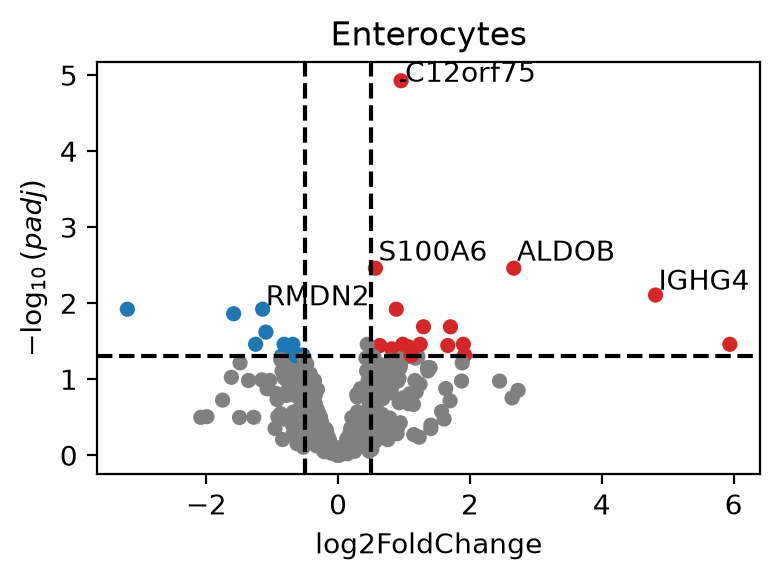


Conducting differential expression analysis in Goblet 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
          baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P   176.238845       -3.153803  0.241300 -13.070049  4.883376e-39  7.872003e-36
LYZ     104.742203       -5.222770  0.550356  -9.489800  2.314783e-21  1.865715e-18
REG4    676.692941       -4.250989  0.491955  -8.641011  5.571777e-18  2.993901e-15
AGR2   2180.985830       -1.720753  0.227847  -7.552233  4.278570e-14  1.724264e-11
F3        8.347726       -2.970572  0.424506  -6.997722  2.601575e-12  8.387478e-10


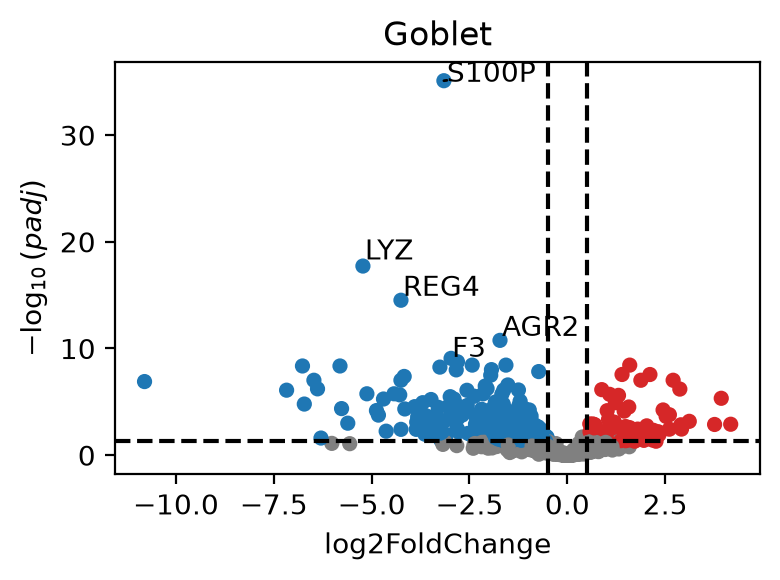

Second condition: healthy vs non-inflammed
         baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P  176.238845       -2.826781  0.227668 -12.416252  2.133225e-35  3.769409e-32
LYZ    104.742203       -5.630239  0.520716 -10.812497  3.003812e-27  2.653868e-24
IGHA1  415.280530       -6.485844  0.820243  -7.907222  2.631969e-15  1.474372e-12
REG4   676.692941       -3.636649  0.461645  -7.877590  3.337571e-15  1.474372e-12
IGJ    219.040208       -7.502227  0.958905  -7.823740  5.127652e-15  1.812112e-12


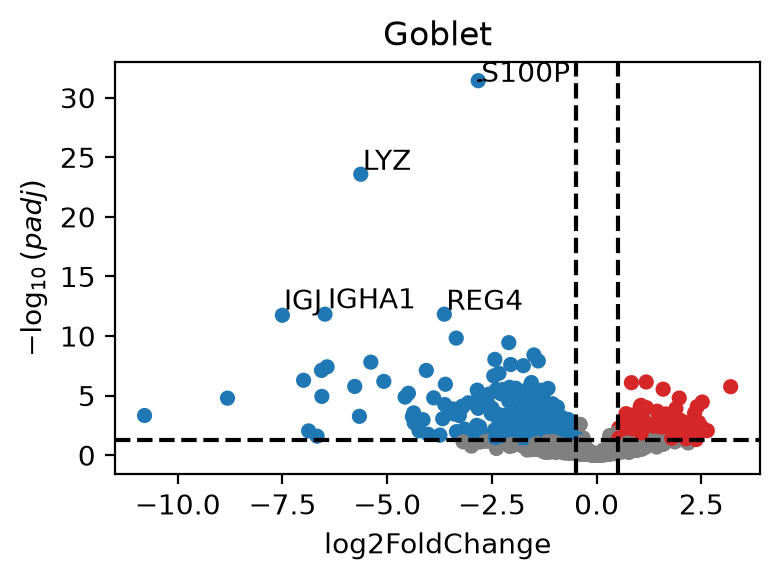

Third condition: inflammed vs non-inflammed
           baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
ITM2A     24.583157       -1.425717  0.360947 -3.949933  0.000078  0.156346
CEACAM5  114.830684        0.718190  0.219613  3.270248  0.001075  0.302513
KLK1     441.213291       -0.578048  0.190467 -3.034899  0.002406  0.302513
SNX29P2    0.715465        2.144379  0.664281  3.228121  0.001246  0.302513
MUC13     46.571192        0.717194  0.227876  3.147299  0.001648  0.302513


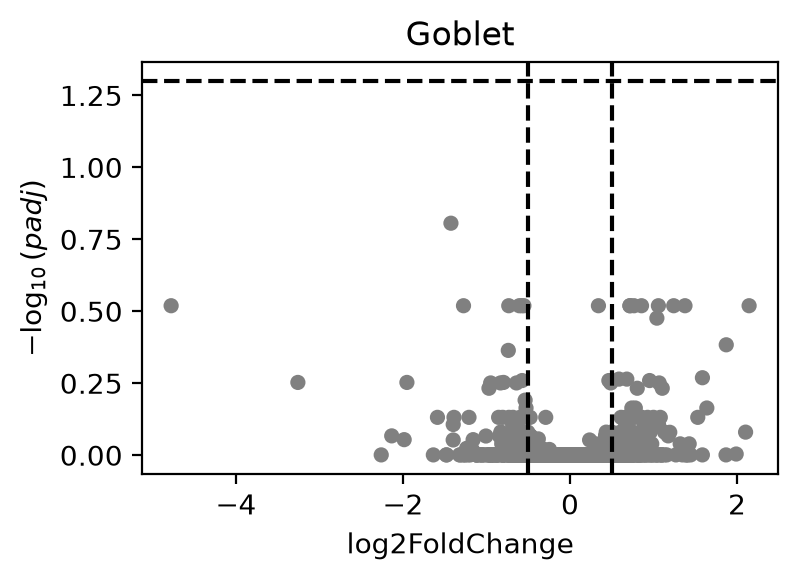


Conducting differential expression analysis in Stem 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
          baseMean  log2FoldChange     lfcSE      stat        pvalue          padj
S100P    24.523581       -7.632394  1.033898 -7.382152  1.557514e-13  1.953123e-10
SOD3     25.196583       -2.343311  0.363374 -6.448763  1.127667e-10  7.070472e-08
CTNNB1   18.434604       -3.119686  0.489714 -6.370429  1.885007e-10  7.879328e-08
PPARG    15.682715        2.281790  0.373369  6.111355  9.878860e-10  3.097023e-07
HNRNPH1  26.759223       -1.926366  0.342183 -5.629630  1.805971e-08  3.774478e-06


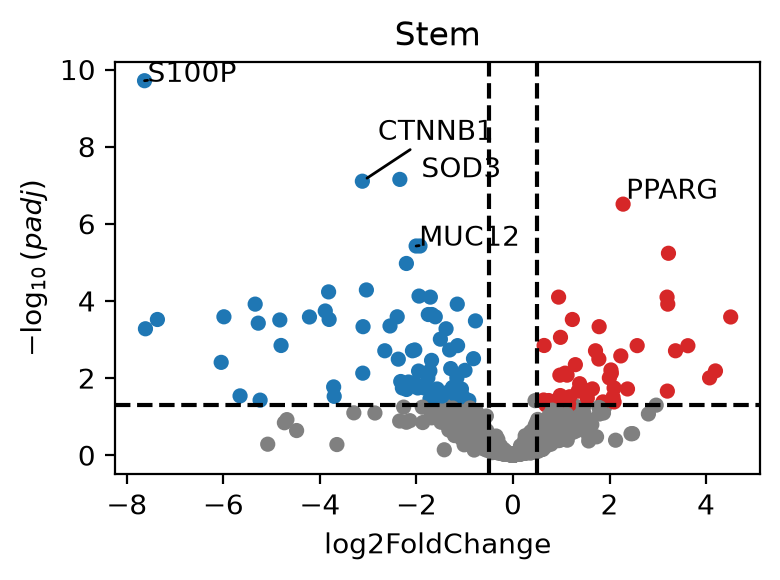

Second condition: healthy vs non-inflammed
          baseMean  log2FoldChange     lfcSE      stat        pvalue          padj
HNRNPH1  26.759223       -1.880925  0.308240 -6.102148  1.046526e-09  5.358211e-07
S100P    24.523581       -6.116100  0.994595 -6.149340  7.780615e-10  5.358211e-07
MDM4      8.290270       -2.223418  0.378761 -5.870243  4.351569e-09  1.114002e-06
CCL20    12.520486       -5.043305  0.854113 -5.904730  3.532248e-09  1.114002e-06
MUC12    76.660386       -1.771304  0.316976 -5.588136  2.295200e-08  3.917141e-06


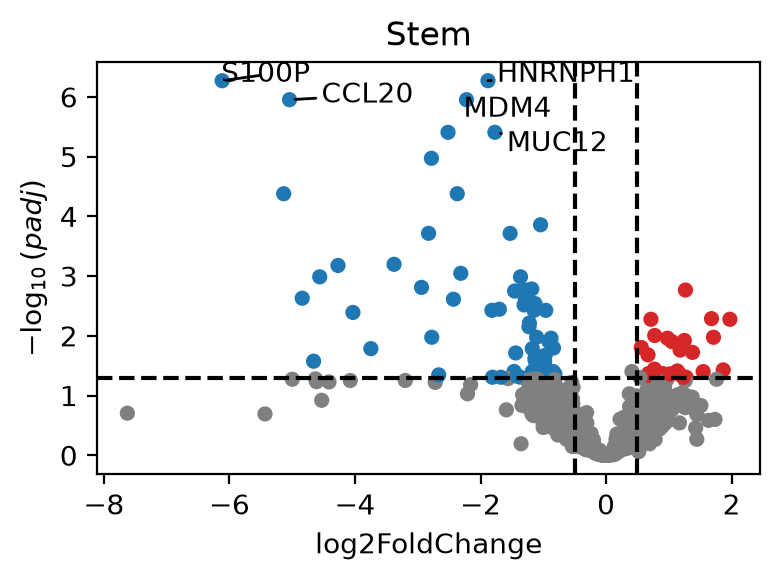

Third condition: inflammed vs non-inflammed
         baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
RNASE1  17.620582        1.537876  0.376176  4.088181  0.000043  0.086345
CLCA1   10.210955       -2.529794  0.698028 -3.624200  0.000290  0.287828
GUCA2A  19.690003       -1.960161  0.602603 -3.252824  0.001143  0.453858
CA4      9.974906       -3.341547  1.014541 -3.293654  0.000989  0.453858
PPARG   15.682715       -1.303165  0.383857 -3.394925  0.000686  0.453858


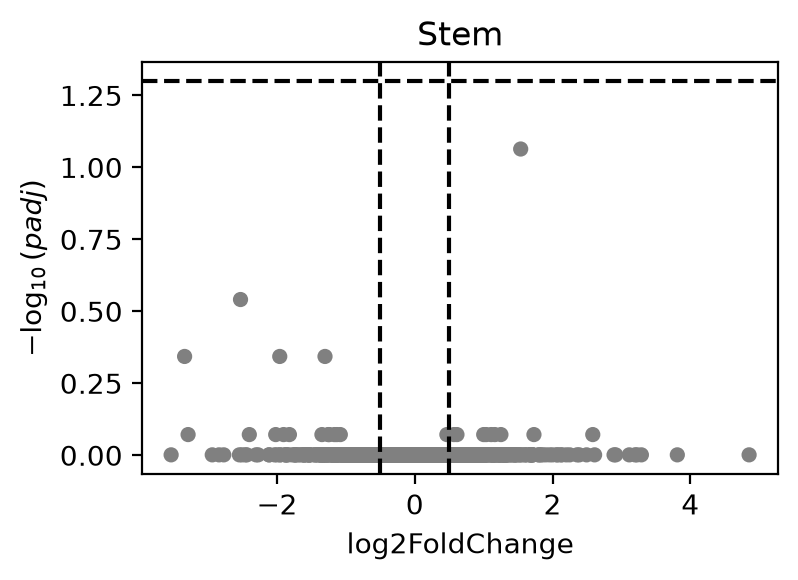


Conducting differential expression analysis in Transit Amplifying 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
          baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P   404.330251       -5.732377  0.321110 -17.851753  2.801039e-71  5.602077e-68
TFF1    233.258131       -5.943982  0.449734 -13.216675  7.030350e-40  7.030350e-37
REG4    724.263103       -6.688786  0.527253 -12.686094  7.062051e-37  4.708034e-34
KDELR3   32.939118       -2.799094  0.230148 -12.162132  4.945110e-34  2.472555e-31
MUC12   250.760822       -2.527127  0.214505 -11.781198  4.879468e-32  1.951787e-29


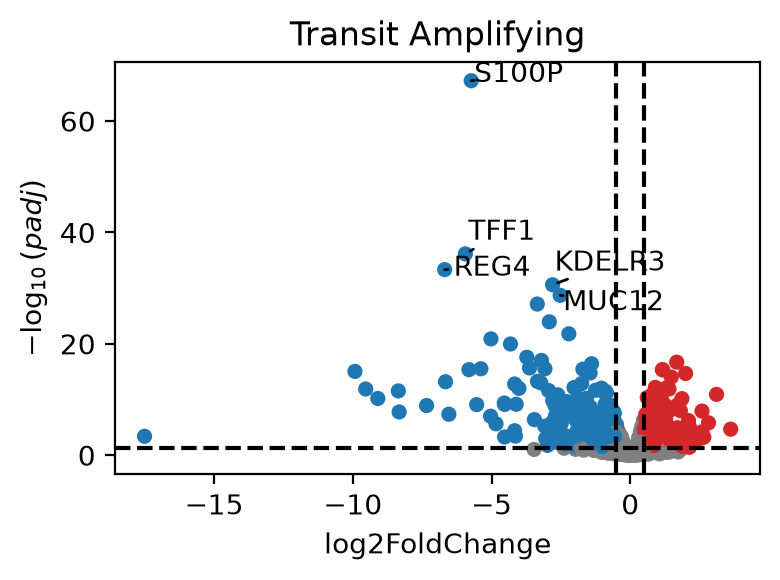

Second condition: healthy vs non-inflammed
          baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P   404.330251       -5.023681  0.311742 -16.114862  2.006109e-58  4.012219e-55
TFF1    233.258131       -4.616513  0.436630 -10.573061  3.973119e-26  3.973119e-23
MUC12   250.760822       -2.172760  0.207980 -10.446969  1.512826e-25  1.008551e-22
KDELR3   32.939118       -2.273306  0.224830 -10.111208  4.927289e-24  2.463644e-21
REG4    724.263103       -4.943470  0.511026  -9.673616  3.903358e-22  1.561343e-19


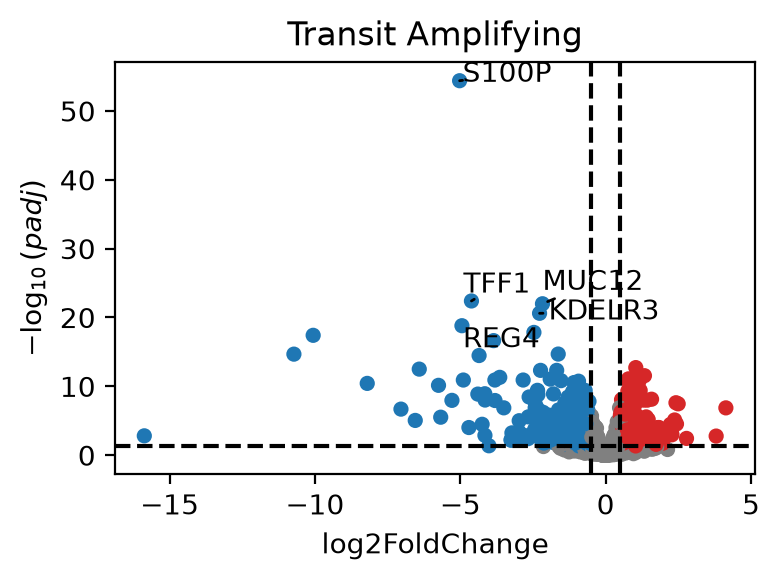

Third condition: inflammed vs non-inflammed
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
PLIN3      50.495107        0.553801  0.143659  3.854980  0.000116  0.034953
SPINK5     88.795147        1.111516  0.278094  3.996908  0.000064  0.034953
KRT19    1671.895344        0.760857  0.220703  3.447425  0.000566  0.048579
CD55      101.157289        0.856449  0.252332  3.394134  0.000688  0.048579
TAX1BP3    98.111769        0.377030  0.116995  3.222622  0.001270  0.048579


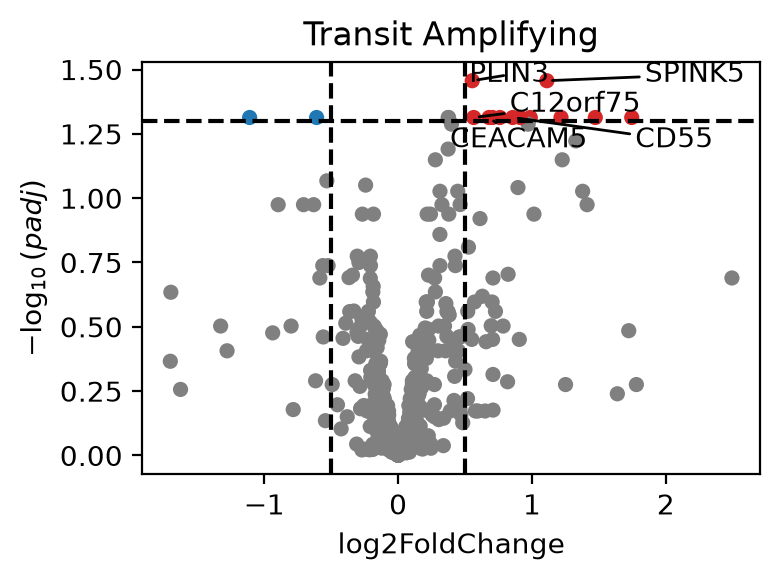

In [ ]:
celltypes_broad = list(pb_ct_adata.obs["cell_type_group"].unique())
inference = DefaultInference(n_cpus=8)

all_celltypes_broad_results_dict = {}

for celltype in celltypes_broad:
    # ensure cell type has all three disease states represented
    if len(pb_ct_adata[pb_ct_adata.obs["cell_type_group"] == celltype].obs["Health"].unique()) != 3:
        continue

    celltype_results_dict = {}

    print("\n=================================================================")
    print("Conducting differential expression analysis in", celltype, "\n")
    dds = DeseqDataSet(
        adata=pb_ct_adata[pb_ct_adata.obs["cell_type_group"] == celltype],
        design="~Health",
        refit_cooks=True,
        inference=inference,
        quiet=True
    )
    dds.deseq2()
    
    print("First condition: healthy vs inflammed")
    healthy_vs_inflamed = PseudobulkedDEA(dds, celltype, "Health", "Healthy", "Inflamed")
    celltype_results_dict["HvI"] = healthy_vs_inflamed

    print("Second condition: healthy vs non-inflammed")
    healthy_vs_noninflamed = PseudobulkedDEA(dds, celltype, "Health", "Healthy", "Non-inflamed")
    celltype_results_dict["HvNI"] = healthy_vs_noninflamed

    print("Third condition: inflammed vs non-inflammed")
    inflamed_vs_noninflamed = PseudobulkedDEA(dds, celltype, "Health", "Inflamed", "Non-inflamed")
    celltype_results_dict["IvNI"] = inflamed_vs_noninflamed

    celltype_results = pd.concat(celltype_results_dict).reset_index(level=0).rename(columns={"level_0": "DEA_condtion"})
    all_celltypes_broad_results_dict[celltype] = celltype_results

all_celltypes_broad_results = pd.concat(all_celltypes_broad_results_dict).reset_index(level=0).rename(columns={"level_0": "DEA_celltype_broad"})


Summary of above outputs:

- Only 4 cells have all three disease states represented for analysis
    - These cell types may not necessarily be more important for disease state than the others, but there is not enough data to say how important the others are (consider other upstream prepocessing decisions to increase data size?)
- S100P and REG4, and TFF1 appear to be significantly downregulated in diseased (I and NI) tissue across multiple cell types
- Generally, there seems to be downregulation of genes driving the difference from health --> diseased, and an upregulation of genes differentiating NI from I (only TA and Enterocytes seem to have strong differences between the latter)


Conducting differential expression analysis in cluster 0 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
           baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P     53.618525       -6.906611  0.524436 -13.169593  1.313027e-39  1.911768e-36
TFF1      32.936340       -6.286655  0.671860  -9.357086  8.196622e-21  5.967141e-18
REG4      70.983790       -8.444528  1.009722  -8.363222  6.102834e-17  2.961909e-14
SPINK4    37.393025       -4.876170  0.587092  -8.305639  9.928357e-17  3.369082e-14
C12orf75  22.422663       -2.004374  0.241856  -8.287456  1.156965e-16  3.369082e-14


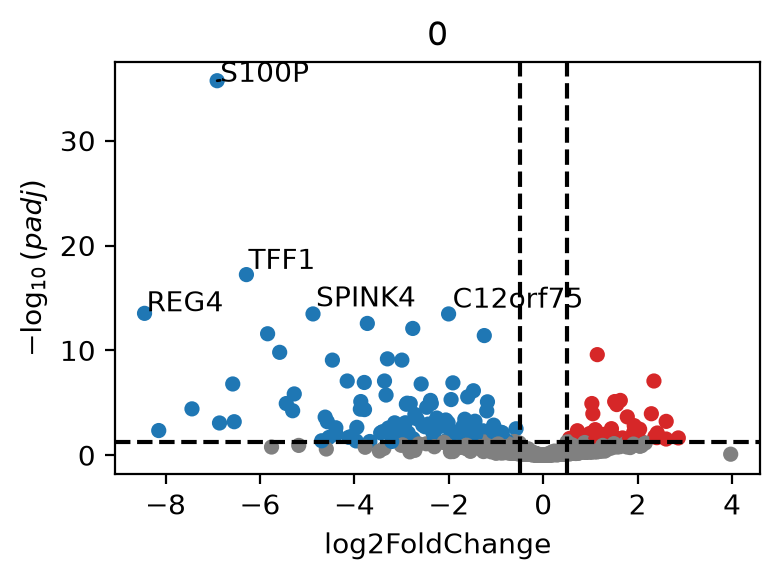

Second condition: healthy vs non-inflammed
           baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P     53.618525       -6.156117  0.466966 -13.183228  1.095989e-39  1.765639e-36
TFF1      32.936340       -4.722729  0.586232  -8.056074  7.878386e-16  6.346040e-13
PLA2G2A  172.400027       -2.346529  0.298695  -7.855943  3.967744e-15  2.130678e-12
REG4      70.983790       -6.722490  0.877024  -7.665118  1.786668e-14  7.195806e-12
SPINK5    16.432471       -2.910160  0.404141  -7.200856  5.983558e-13  1.671159e-10


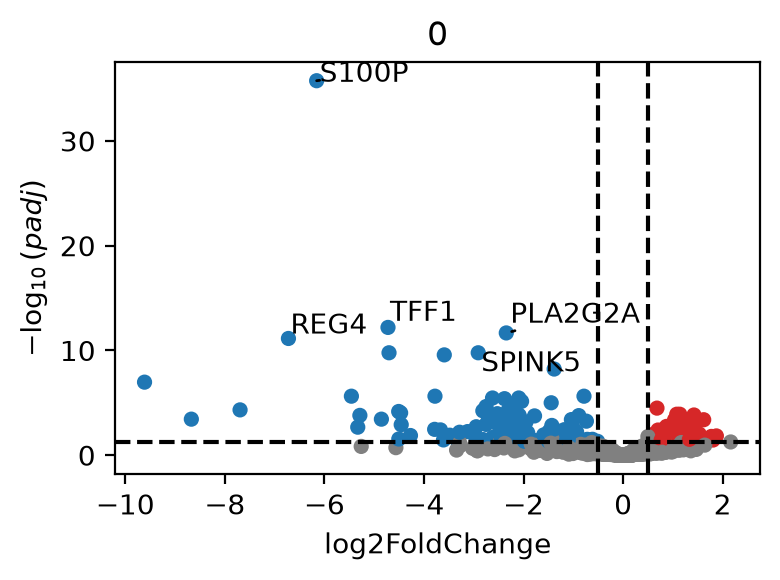

Third condition: inflammed vs non-inflammed
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
RNA28S5    18.341901       -2.412596  0.630008 -3.829466  0.000128  0.256714
S100A6   1151.247619        0.462293  0.166183  2.781825  0.005405  0.677164
ASCL2       9.534904        0.855158  0.319939  2.672879  0.007520  0.677164
MLF1IP      4.991521        1.427168  0.427039  3.342006  0.000832  0.677164
CD14        3.278345       -1.426323  0.551003 -2.588594  0.009637  0.677164


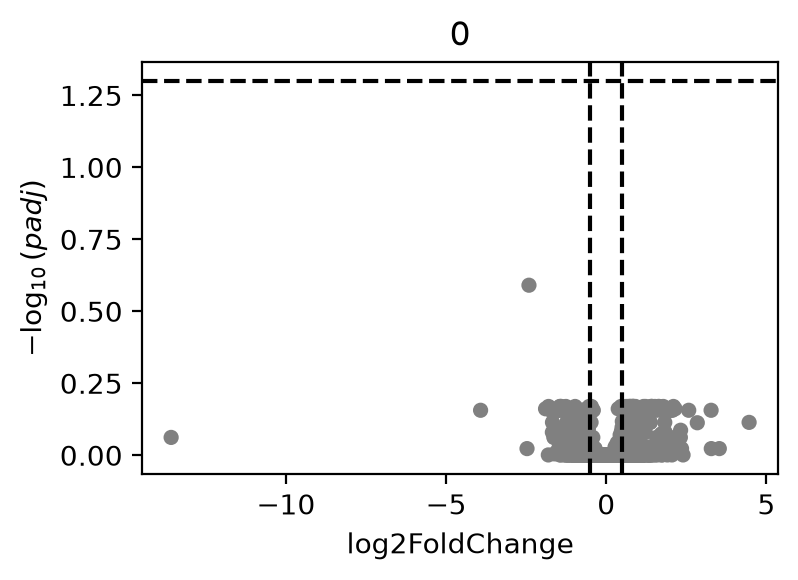


Conducting differential expression analysis in cluster 1 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
           baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P    300.771246       -6.507555  0.383587 -16.965022  1.490435e-64  2.575472e-61
PLA2G2A  483.997428       -5.792766  0.450951 -12.845676  9.095371e-38  7.858400e-35
TFF1     839.376306       -5.863943  0.507814 -11.547414  7.607471e-31  4.381903e-28
CTSE      29.055778       -6.834322  0.620302 -11.017735  3.138565e-28  1.355860e-25
REG4     494.837571      -10.245000  0.972834 -10.531091  6.211067e-26  2.146545e-23


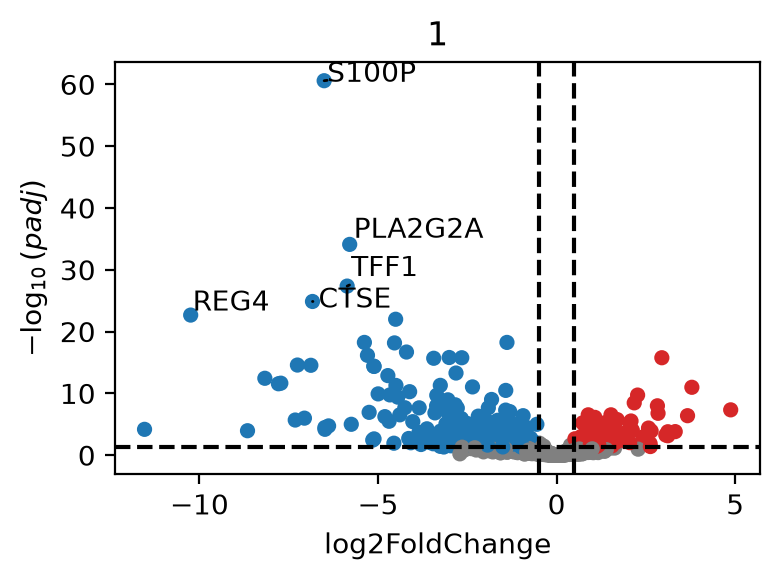

Second condition: healthy vs non-inflammed
           baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P    300.771246       -5.783451  0.378950 -15.261781  1.374452e-52  2.375054e-49
PLA2G2A  483.997428       -5.315887  0.445039 -11.944761  6.914870e-33  5.974448e-30
WFDC2     33.080646       -4.531735  0.456297  -9.931547  3.035097e-23  1.748216e-20
SPINK5    54.505975       -3.973071  0.429558  -9.249202  2.261756e-20  9.770785e-18
TFF1     839.376306       -4.549443  0.501102  -9.078874  1.097041e-19  3.791374e-17


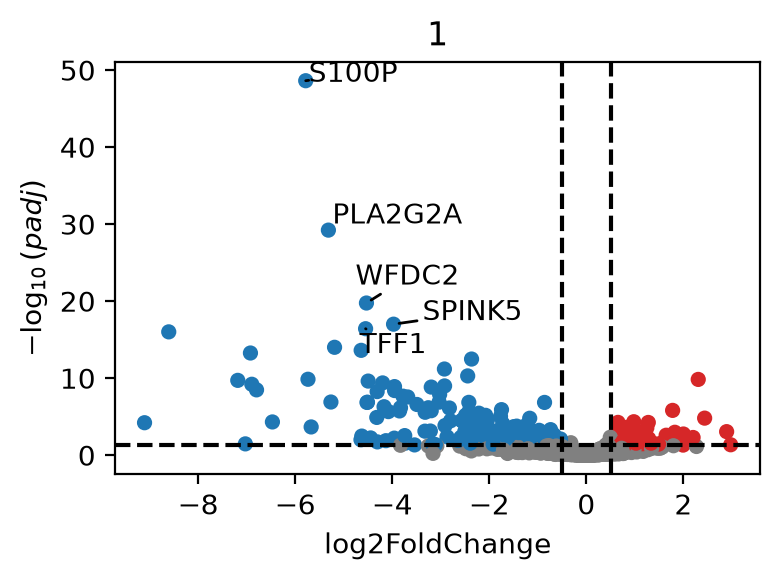

Third condition: inflammed vs non-inflammed
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
ALDH3A1     5.308639        2.707137  0.608285  4.450441  0.000009  0.017139
PYY         5.335592       -3.181038  0.770383 -4.129162  0.000036  0.036409
C12orf75  123.678230        0.822533  0.206294  3.987182  0.000067  0.044575
ASNS        2.028609        1.937991  0.506413  3.826900  0.000130  0.051907
ALDOB      16.219170        2.500872  0.651777  3.837006  0.000125  0.051907


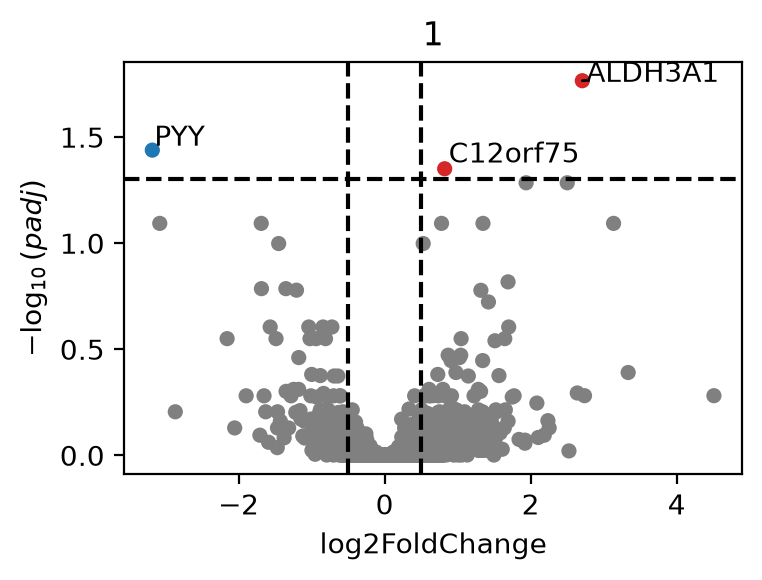


Conducting differential expression analysis in cluster 2 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
            baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P     246.369072       -4.071000  0.280825 -14.496594  1.273113e-47  2.446924e-44
LYZ       223.290438       -5.612571  0.486207 -11.543573  7.955069e-31  7.644821e-28
REG4      841.576580       -4.550932  0.476039  -9.560000  1.177563e-21  7.544252e-19
PPARG      17.828631        1.846575  0.197559   9.346963  9.020018e-21  4.334119e-18
SELENBP1  104.812352        2.212663  0.268320   8.246354  1.633004e-16  6.277266e-14


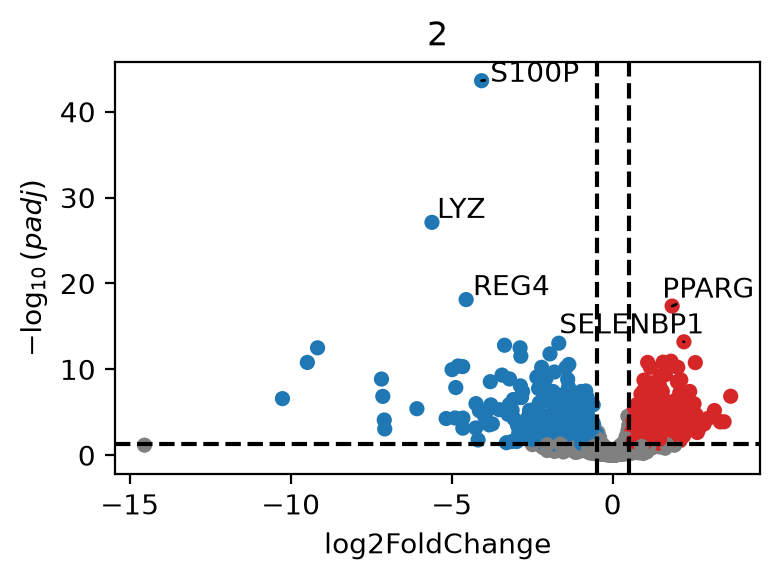

Second condition: healthy vs non-inflammed
                  baseMean  log2FoldChange     lfcSE       stat        pvalue  \
S100P           246.369072       -3.694277  0.262856 -14.054354  7.243959e-45   
LYZ             223.290438       -6.002198  0.455609 -13.174014  1.238343e-39   
DEFA6          1010.588650      -10.362761  1.073676  -9.651661  4.836579e-22   
REG4            841.576580       -3.984691  0.443295  -8.988803  2.499369e-19   
RP11-1143G9.4    18.899964       -6.044751  0.734785  -8.226551  1.926805e-16   

                       padj  
S100P          1.420540e-41  
LYZ            1.214195e-36  
DEFA6          3.161510e-19  
REG4           1.225316e-16  
RP11-1143G9.4  7.115493e-14  


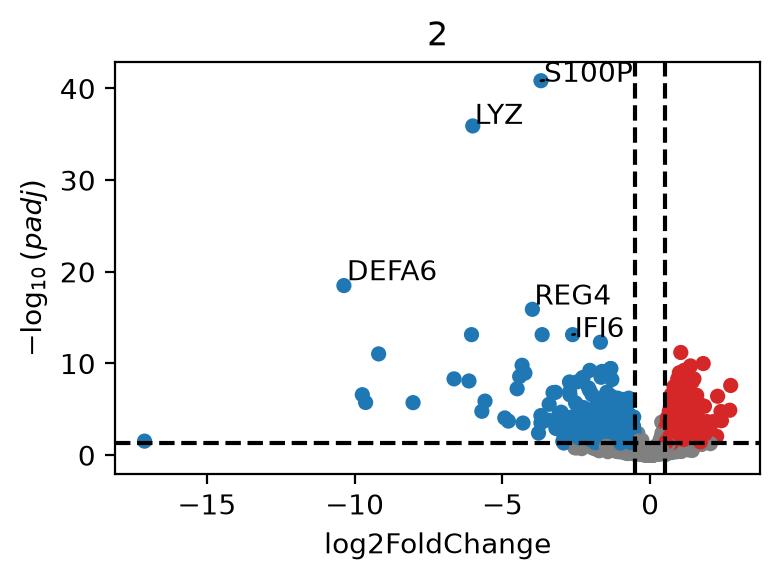

Third condition: inflammed vs non-inflammed
            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
CTSE        3.550147        1.290458  0.387793  3.327700  0.000876  0.175132
MUC13      71.023142        0.673982  0.194479  3.465574  0.000529  0.175132
ANKRD36C    6.765167        1.157215  0.331654  3.489223  0.000484  0.175132
GSN       197.931171        0.820511  0.224784  3.650213  0.000262  0.175132
PPARG      17.828631       -0.649526  0.194812 -3.334122  0.000856  0.175132


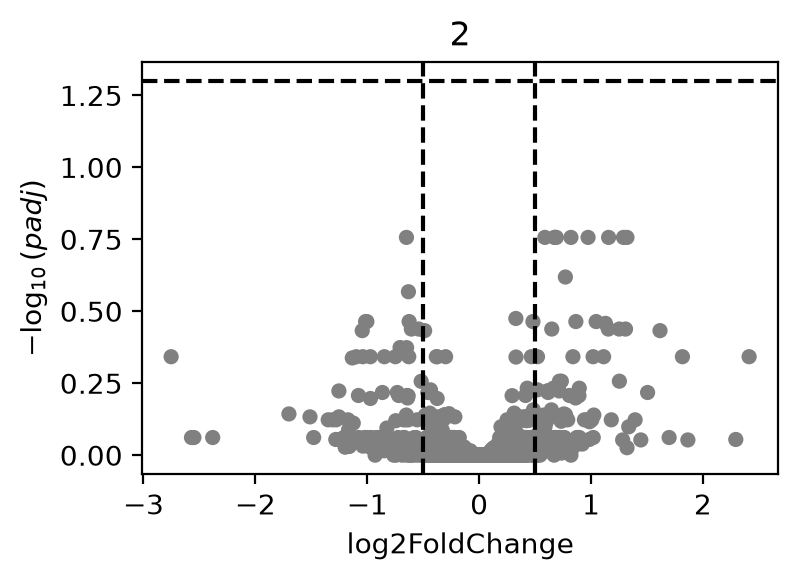


Conducting differential expression analysis in cluster 3 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
          baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P   275.446895       -5.695408  0.324795 -17.535392  7.691713e-69  1.538343e-65
SPINK5   45.980901       -3.702618  0.338478 -10.939017  7.500872e-28  7.500872e-25
KDELR3   26.128161       -2.884495  0.267413 -10.786680  3.979050e-27  2.652700e-24
MUC12   194.535769       -2.343279  0.224667 -10.430026  1.808383e-25  9.041913e-23
TFF1    129.237455       -4.898560  0.471517 -10.388944  2.784183e-25  1.113673e-22


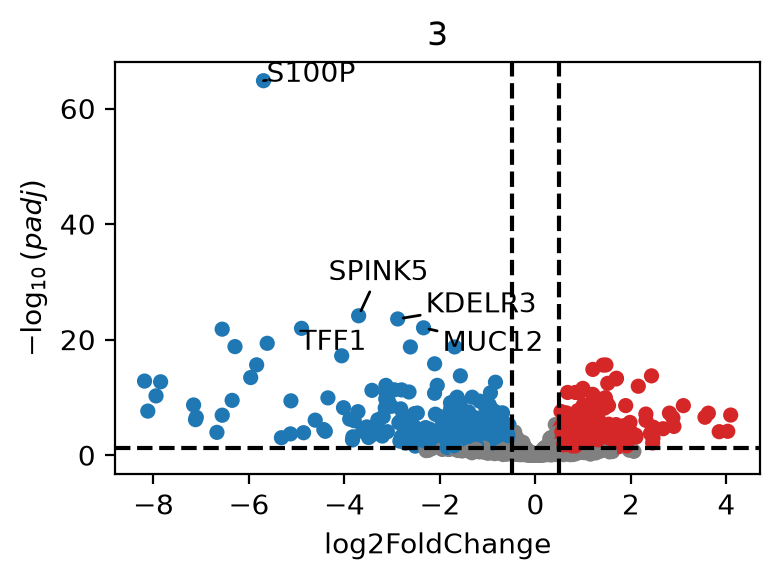

Second condition: healthy vs non-inflammed
            baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P     275.446895       -5.108158  0.311123 -16.418429  1.411748e-60  2.823496e-57
HLA-DPB1   90.666681       -5.790716  0.626970  -9.236036  2.557989e-20  2.557989e-17
KDELR3     26.128161       -2.273227  0.258925  -8.779467  1.642517e-18  1.022543e-15
REG4      494.735329       -5.293557  0.604648  -8.754776  2.045086e-18  1.022543e-15
LYZ       265.780902       -3.656530  0.420081  -8.704353  3.193920e-18  1.277568e-15


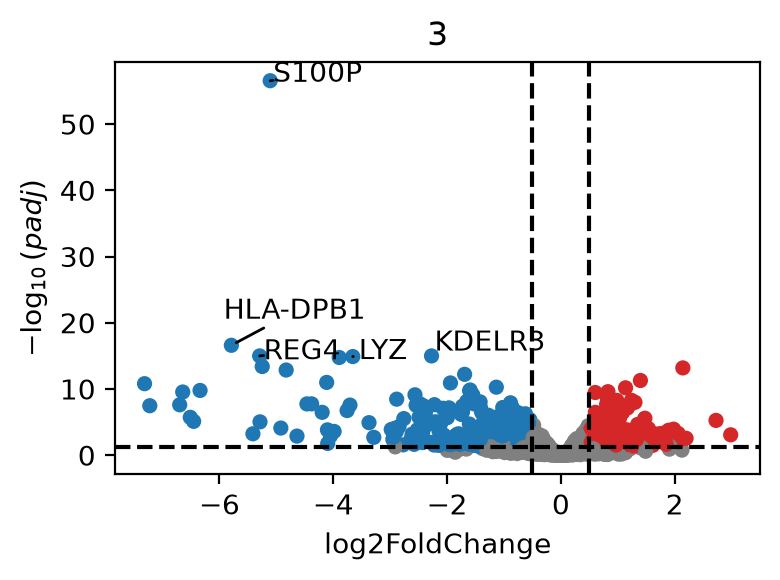

Third condition: inflammed vs non-inflammed
            baseMean  log2FoldChange     lfcSE      stat        pvalue      padj
SPINK5     45.980901        1.736475  0.306311  5.668987  1.436443e-08  0.000015
SEPP1      31.895260        1.287929  0.290580  4.432274  9.324444e-06  0.004807
C12orf75  138.071784        0.670096  0.165543  4.047856  5.168894e-05  0.017764
UGDH       98.564190       -0.390223  0.103430 -3.772815  1.614161e-04  0.027737
TRIM31     12.380554        1.007227  0.265121  3.799119  1.452115e-04  0.027737


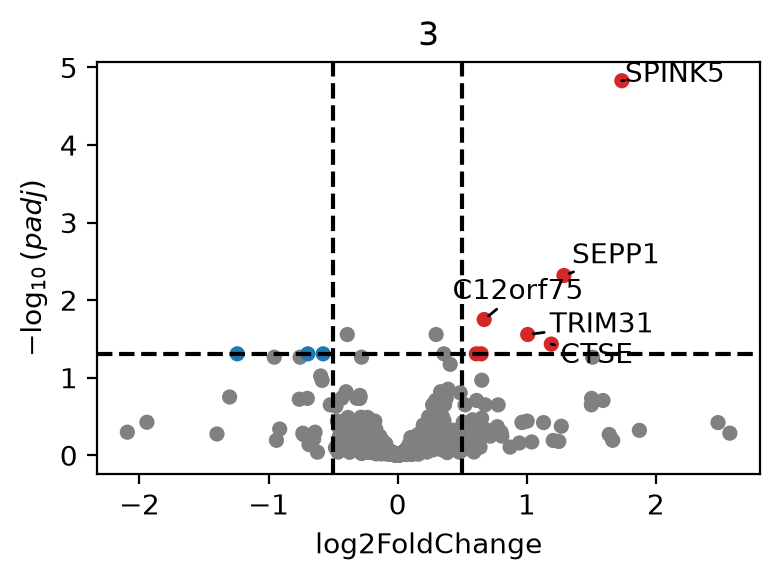


Conducting differential expression analysis in cluster 4 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
          baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P   330.743330       -5.938144  0.365770 -16.234618  2.870282e-59  5.516683e-56
TFF1    192.775000       -6.751000  0.512110 -13.182710  1.103549e-39  1.060511e-36
MUC12   195.708083       -2.761161  0.236108 -11.694504  1.359791e-31  8.711728e-29
SPINK5  116.260366       -3.891016  0.347292 -11.203888  3.902237e-29  1.875025e-26
REG4    367.424656       -7.590410  0.694662 -10.926762  8.585765e-28  3.300368e-25


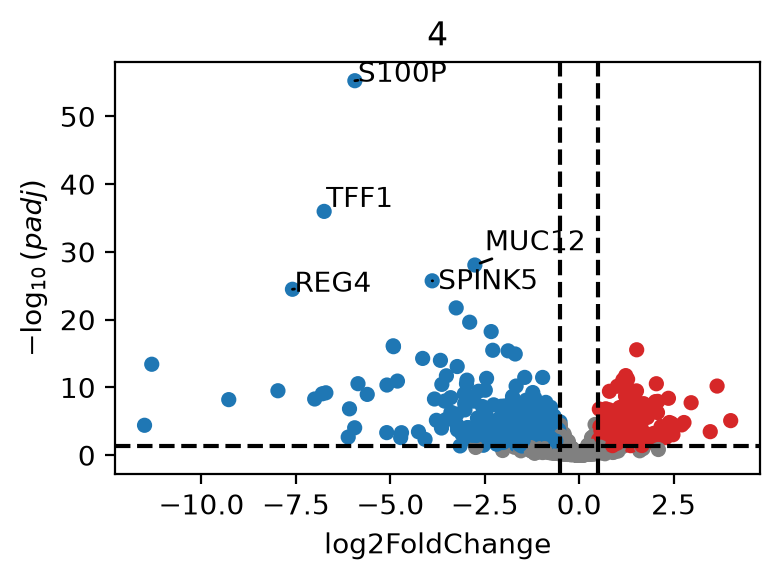

Second condition: healthy vs non-inflammed
           baseMean  log2FoldChange     lfcSE       stat        pvalue          padj
S100P    330.743330       -5.336756  0.343200 -15.550009  1.590846e-54  2.995564e-51
TFF1     192.775000       -5.859012  0.481603 -12.165647  4.736770e-34  4.459669e-31
MUC12    195.708083       -2.167575  0.221024  -9.806980  1.050662e-22  6.594656e-20
REG4     367.424656       -6.336339  0.650369  -9.742688  1.982399e-22  9.332142e-20
PLA2G2A  907.693572       -2.745817  0.294236  -9.332016  1.038763e-20  3.911983e-18


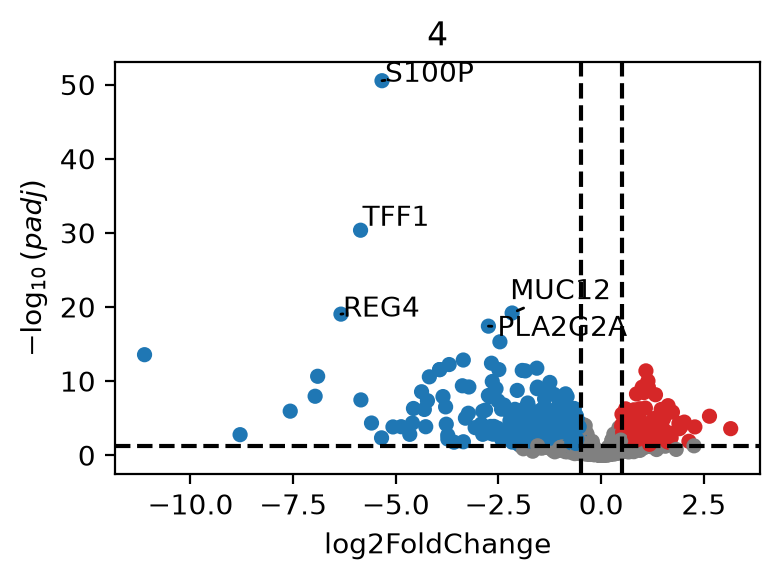

Third condition: inflammed vs non-inflammed
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
SPINK5  116.260366        1.399477  0.335797  4.167633  0.000031  0.012619
UGT2A3   44.891040       -1.254421  0.330146 -3.799595  0.000145  0.029711
MSMO1    23.315750        0.767061  0.217420  3.528018  0.000419  0.042915
SEPP1    48.460066        1.305183  0.365549  3.570470  0.000356  0.042915
CENPW    26.768208        0.693918  0.202985  3.418562  0.000630  0.043018


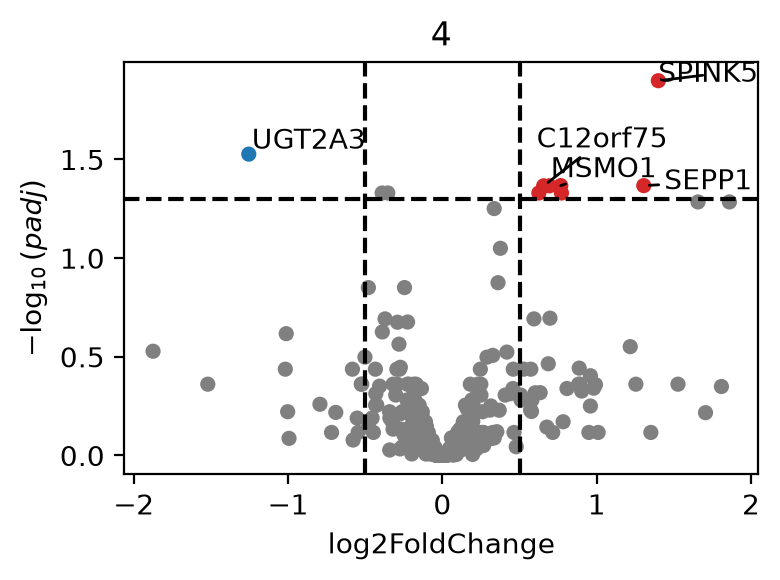


Conducting differential expression analysis in cluster 6 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
        baseMean  log2FoldChange     lfcSE      stat        pvalue          padj
MDK    12.295560       -3.295362  0.549731 -5.994498  2.041155e-09  9.083139e-07
S100P  30.113912       -5.933646  1.030820 -5.756236  8.600994e-09  1.913721e-06
CD74   65.423963       -4.756886  0.880236 -5.404101  6.513419e-08  9.661572e-06
MUC12  43.054594       -4.401149  0.935564 -4.704274  2.547715e-06  2.834333e-04
SOD3    6.394217       -4.305957  0.932435 -4.617968  3.875162e-06  3.448894e-04


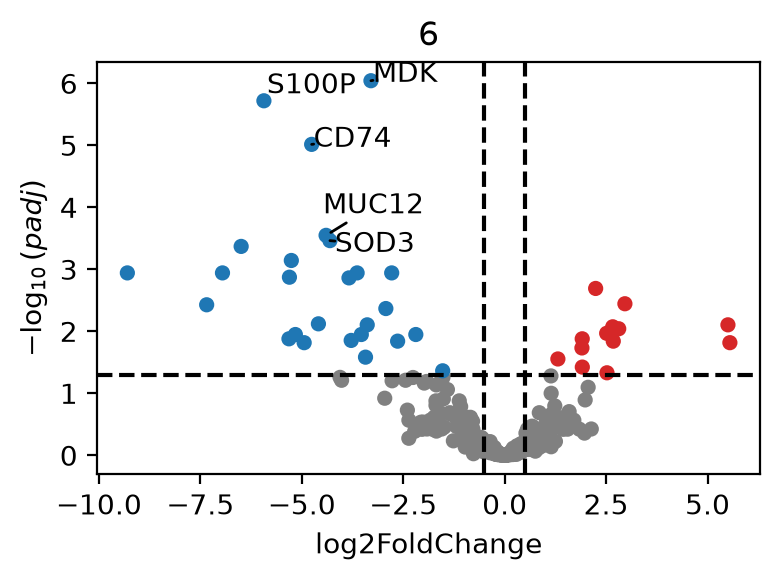

Second condition: healthy vs non-inflammed
        baseMean  log2FoldChange     lfcSE      stat        pvalue      padj
S100P  30.113912       -5.697378  0.998449 -5.706229  1.155066e-08  0.000003
ETNK1  14.721361        2.580499  0.526679  4.899564  9.604968e-07  0.000102
WFDC2  27.705743       -4.352331  0.891398 -4.882589  1.047019e-06  0.000102
LYZ    16.263234       -5.517871  1.240322 -4.448740  8.637531e-06  0.000631
CD74   65.423963       -3.525684  0.838734 -4.203576  2.627308e-05  0.001304


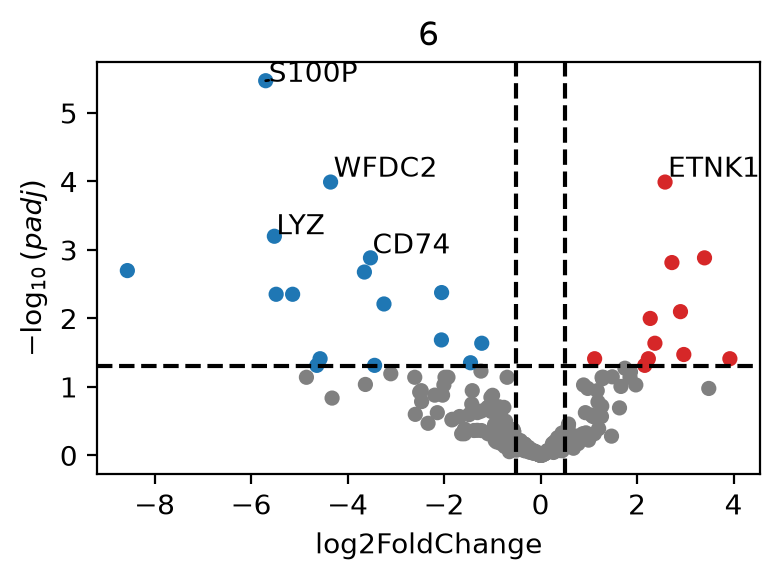

Third condition: inflammed vs non-inflammed
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
SEPP1     8.107256        2.148479  0.522322  4.113322  0.000039  0.077104
CEACAM5  33.266862        1.488932  0.443338  3.358457  0.000784  0.516517
MDK      12.295560        1.244010  0.370289  3.359564  0.000781  0.516517
CEACAM6   4.703984        2.029417  0.644928  3.146735  0.001651  0.652823
GBP2      1.489579        2.393459  0.748093  3.199414  0.001377  0.652823


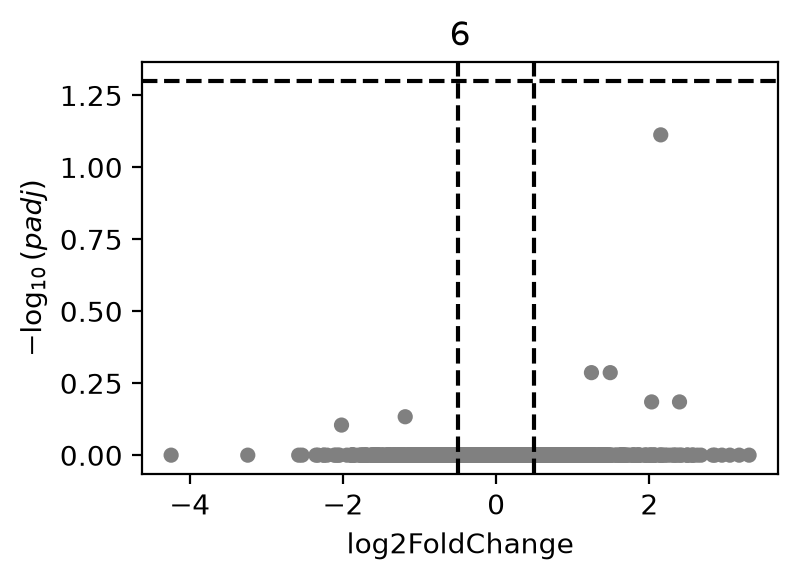


Conducting differential expression analysis in cluster 7 

Error: Not enough replicates! Samples: 3, Variables: 3

Conducting differential expression analysis in cluster 8 



/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)
/Users/makayla/Library/Mobile Documents/com~apple~CloudDocs/School/09615-ML/UC_Discovery_Project/ML_project/lib/python3.13/site-packages/pydeseq2/dds.py:245: ImplicitModificationWarning: Setting element `.X` of view, initializing view as actual.
  self.X = adata.X.astype(int)


First condition: healthy vs inflammed
                 baseMean  log2FoldChange     lfcSE      stat        pvalue          padj
S100P          141.487490       -5.037057  0.587230 -8.577653  9.682822e-18  1.323642e-14
AQP8           177.625572        5.257417  0.853634  6.158864  7.326884e-10  5.007925e-07
CTNNB1          25.942272       -2.940801  0.503320 -5.842803  5.132976e-09  2.338926e-06
ANPEP           34.394548        3.681187  0.654964  5.620444  1.904675e-08  3.573097e-06
RP11-1143G9.4    3.354524       -4.854122  0.866143 -5.604294  2.091059e-08  3.573097e-06


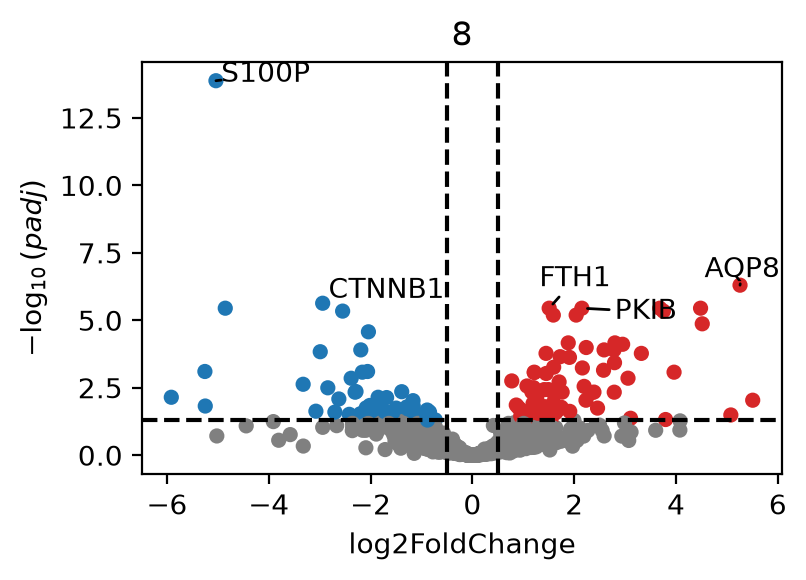

Second condition: healthy vs non-inflammed
             baseMean  log2FoldChange     lfcSE      stat        pvalue          padj
S100P      141.487490       -4.185835  0.503883 -8.307157  9.802231e-17  1.227239e-13
AQP8       177.625572        4.419560  0.707319  6.248327  4.148711e-10  2.597093e-07
FTH1      5476.462900        1.378487  0.225847  6.103647  1.036754e-09  4.326718e-07
APOBEC3B    12.813226        3.500622  0.605940  5.777175  7.596531e-09  2.377714e-06
WFDC2       65.680633       -2.204166  0.394742 -5.583815  2.352984e-08  5.891872e-06


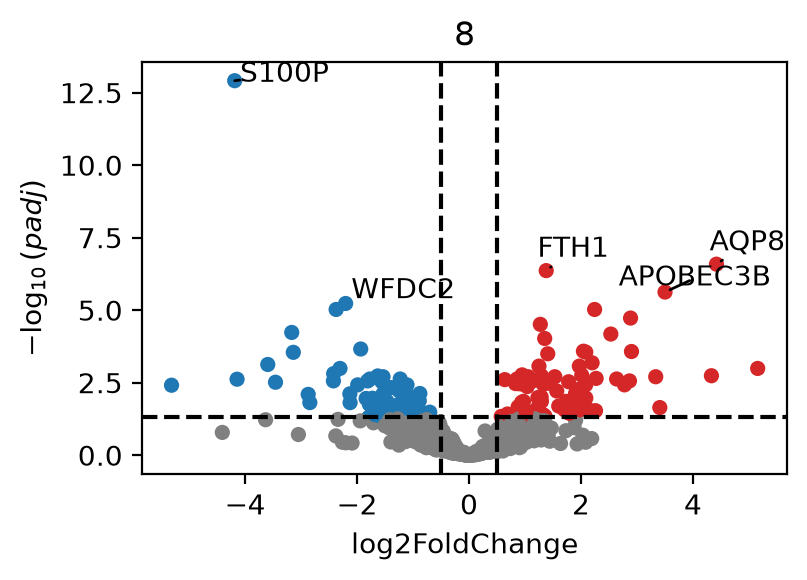

Third condition: inflammed vs non-inflammed
         baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
AARS     4.864896        0.309381  0.545212  0.567452  0.570407  0.999053
PTPRCAP  0.776123       -0.166883  1.280251 -0.130351  0.896288  0.999053
PTPRC    0.399222        0.511350  1.477952  0.345985  0.729354  0.999053
PTPN6    5.180448        0.685136  0.465799  1.470884  0.141322  0.999053
PTPN4    1.570624        0.032039  0.669608  0.047847  0.961838  0.999053


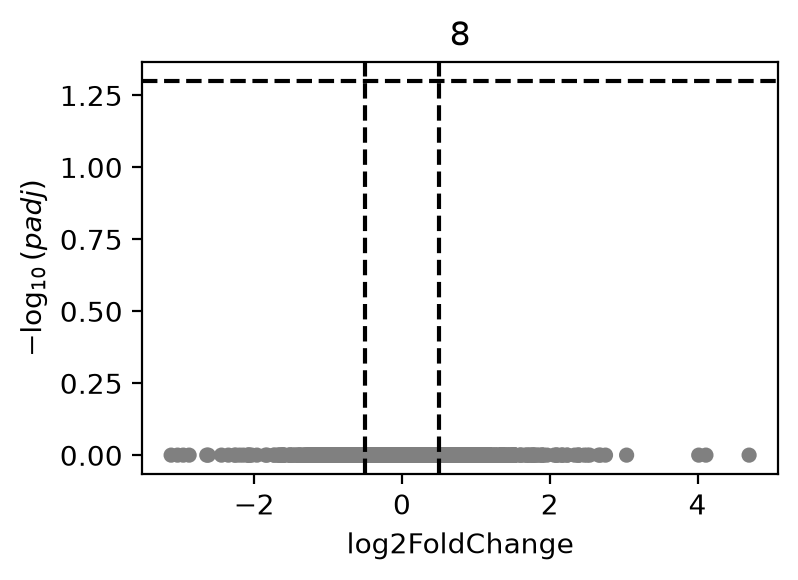

In [79]:
clusters= list(pb_cl_adata.obs["leiden"].unique())
inference = DefaultInference(n_cpus=8)

all_clusters_results_dict = {}

for cluster in clusters:
    # ensure cell type has all three disease states represented
    if len(pb_cl_adata[pb_cl_adata.obs["leiden"] == cluster].obs["Health"].unique()) != 3:
        continue

    cluster_results_dict = {}

    print("\n=================================================================")
    print("Conducting differential expression analysis in cluster", cluster, "\n")
    dds = DeseqDataSet(
        adata=pb_cl_adata[pb_cl_adata.obs["leiden"] == cluster],
        design="~Health",
        refit_cooks=True,
        inference=inference,
        quiet=True
    )
    if dds.n_obs <= 3:
        print(f"Error: Not enough replicates! Samples: {dds.n_obs}, Variables: 3")
        continue

    dds.deseq2()
    
    print("First condition: healthy vs inflammed")
    healthy_vs_inflamed = PseudobulkedDEA(dds, cluster, "Health", "Healthy", "Inflamed")
    cluster_results_dict["HvI"] = healthy_vs_inflamed

    print("Second condition: healthy vs non-inflammed")
    healthy_vs_noninflamed = PseudobulkedDEA(dds, cluster, "Health", "Healthy", "Non-inflamed")
    cluster_results_dict["HvNI"] = healthy_vs_noninflamed

    print("Third condition: inflammed vs non-inflammed")
    inflamed_vs_noninflamed = PseudobulkedDEA(dds, cluster, "Health", "Inflamed", "Non-inflamed")
    cluster_results_dict["IvNI"] = inflamed_vs_noninflamed

    cluster_results = pd.concat(cluster_results_dict).reset_index(level=0).rename(columns={"level_0": "DEA_condtion"})
    all_clusters_results_dict[cluster] = cluster_results

all_cluster_results = pd.concat(all_clusters_results_dict).reset_index(level=0).rename(columns={"level_0": "DEA_cluster"})


### Now visualize the mst significant DE genes

- If a DE gene separates with a cell type/cluster by disease state, no need to re-cluster
- Otherwise, cal re-cluster using the following format, then rerun DEA on each sub-cluster:


        Isolate cluster 3 and re-cluster
        adata_sub = adata[adata.obs["leiden"] == "3"].copy()
        sc.tl.leiden(adata_sub, resolution=0.3, key_added="sub_leiden")
        sc.pl.umap(adata_sub, color="sub_leiden")

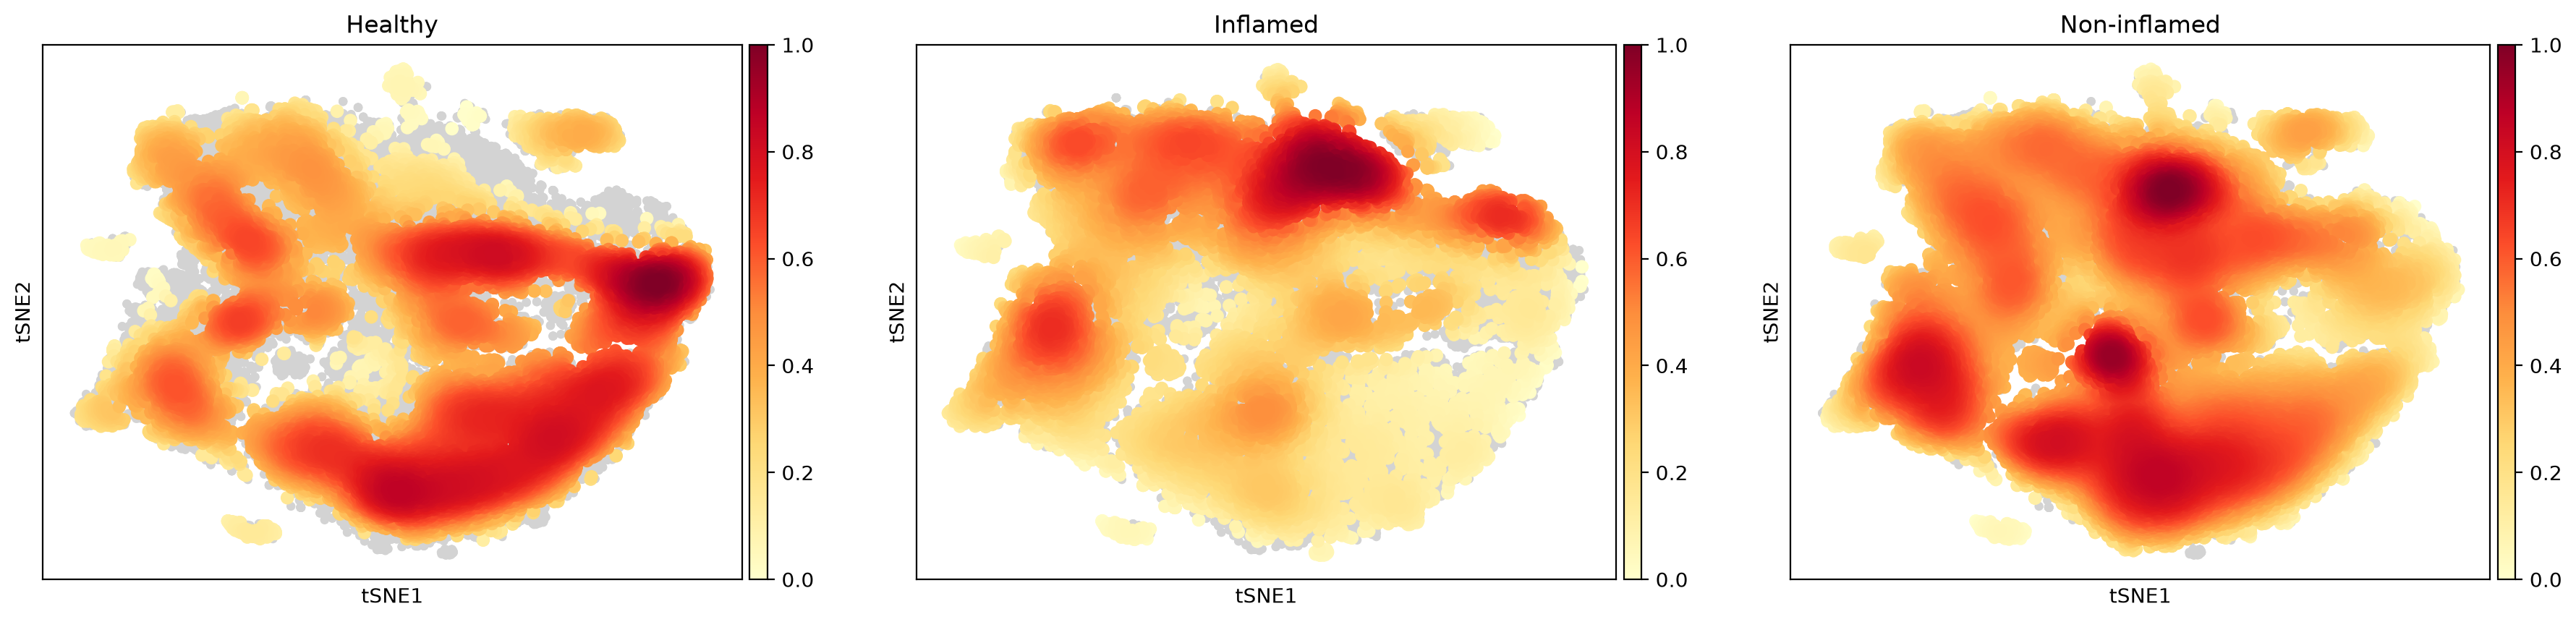

In [85]:
sc.tl.embedding_density(sc_adata, basis='tsne', groupby='Health')
sc.pl.embedding_density(sc_adata, basis='tsne', key='tsne_density_Health')

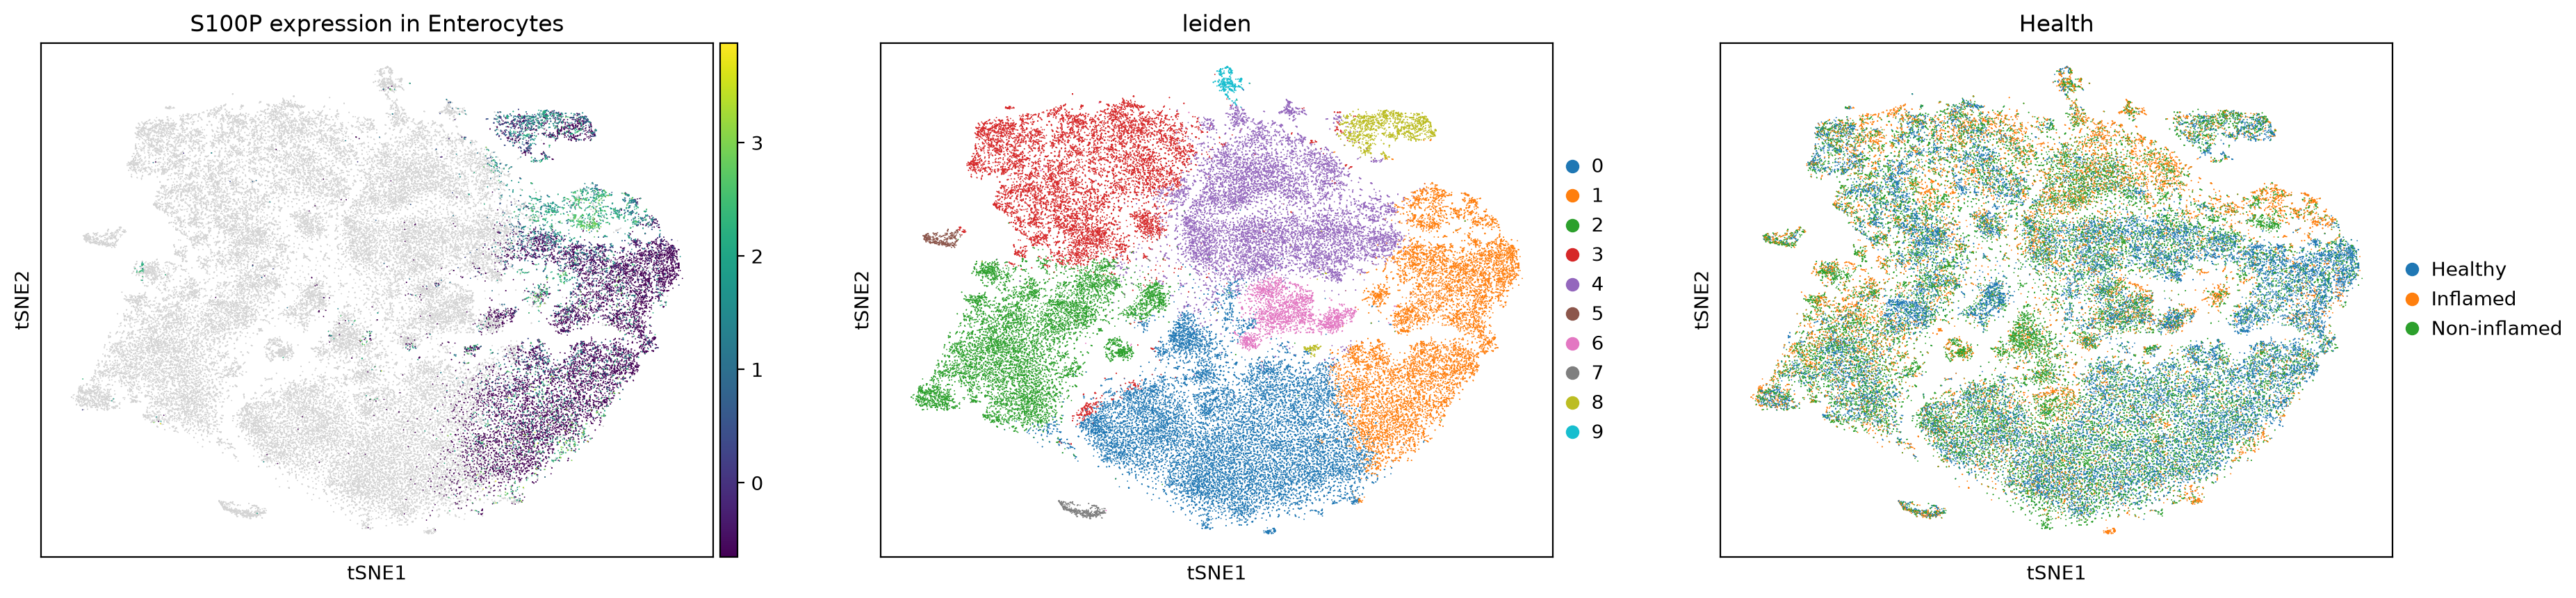

In [ ]:
gene_name = "S100P"
target_cell_type = "Enterocytes"

# Add a temporary column to adata.obs containing the gene values, fill non-target cells with NaN
sc_adata.obs["target_gene_expr"] = sc_adata.obs_vector(gene_name)
sc_adata.obs.loc[sc_adata.obs["cell_type_group"] != target_cell_type, "target_gene_expr"] = np.nan

sc.pl.embedding(
    sc_adata, 
    basis="tsne", 
    color=["target_gene_expr", "leiden", "Health"], 
    cmap="viridis",
    title=f"{gene_name} expression in {target_cell_type}"
)

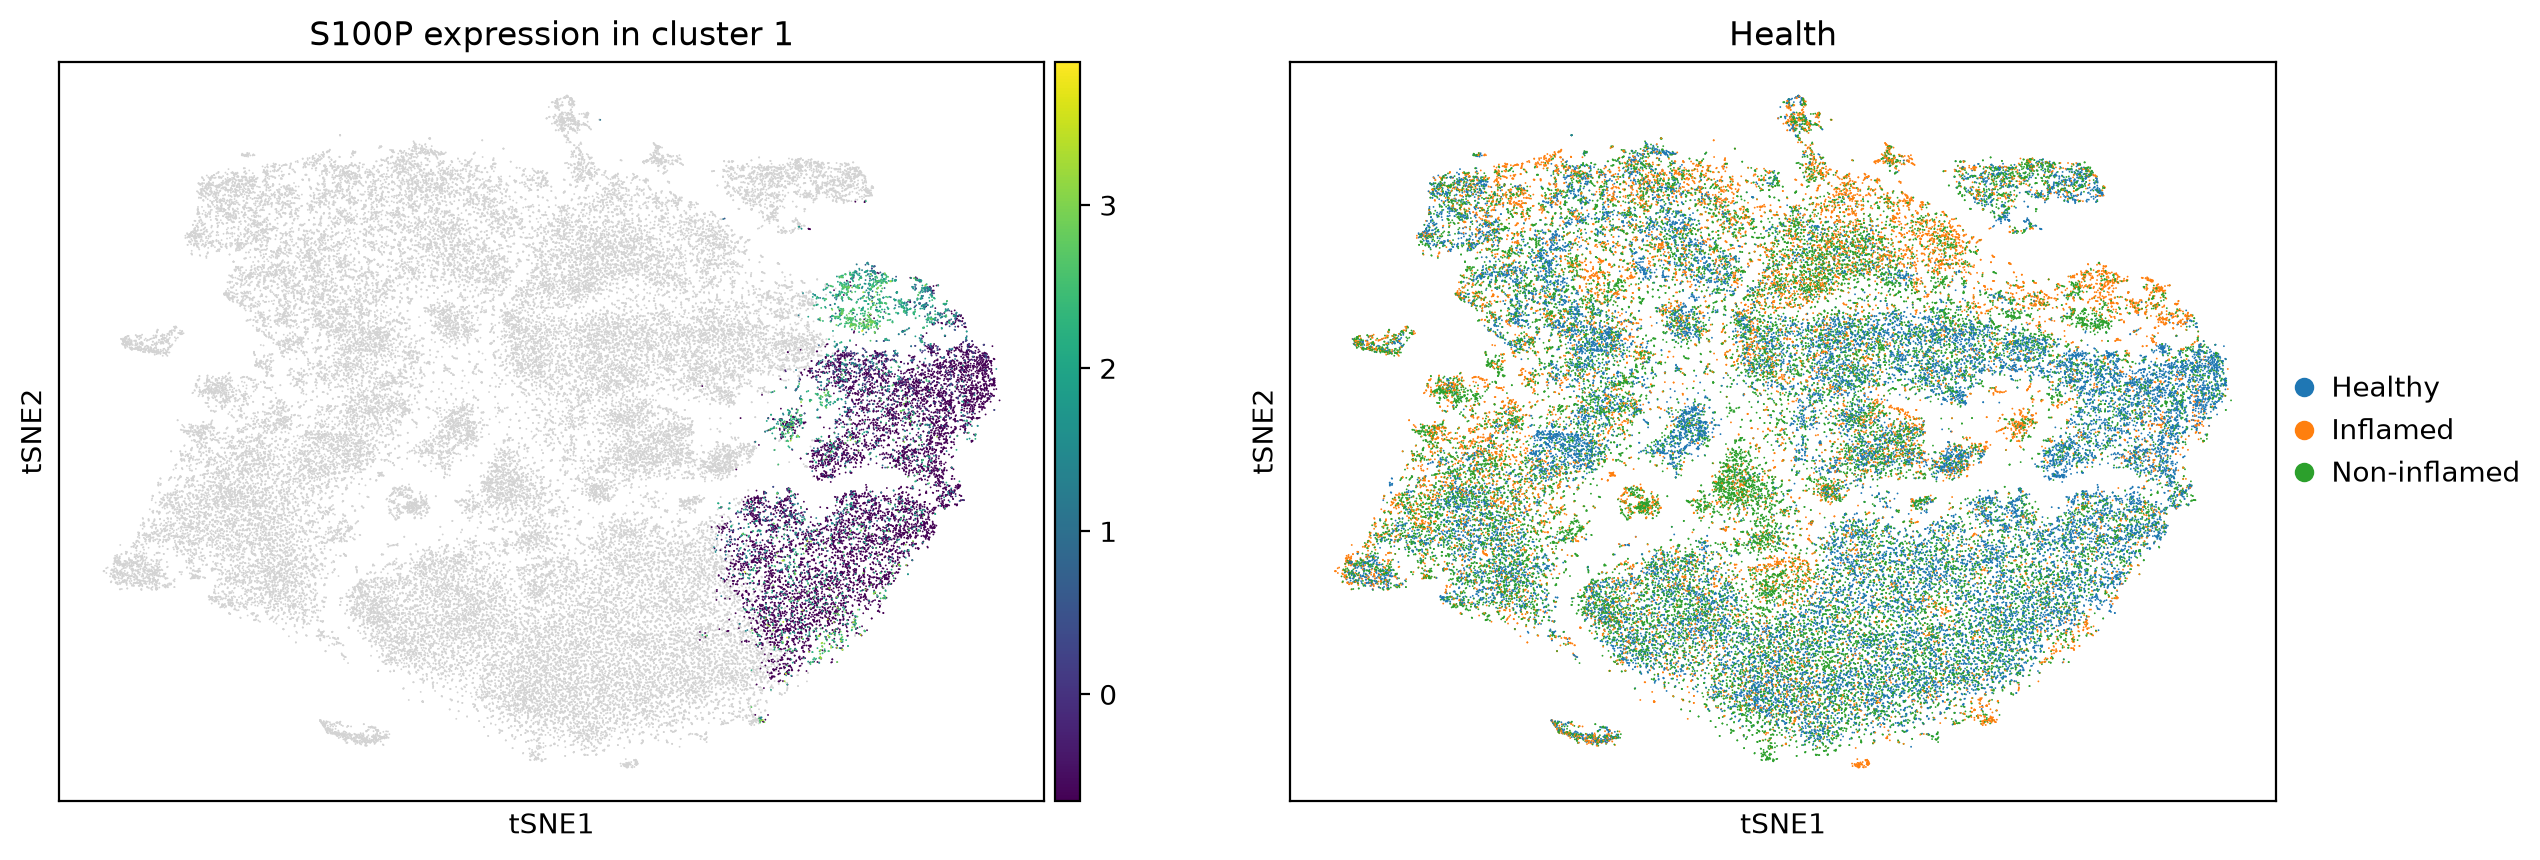

In [83]:
gene_name = "S100P"
target_cluster = "1"

# Add a temporary column to adata.obs containing the gene values, fill non-target cells with NaN
sc_adata.obs["target_gene_expr"] = sc_adata.obs_vector(gene_name)
sc_adata.obs.loc[sc_adata.obs["leiden"] != target_cluster, "target_gene_expr"] = np.nan

sc.pl.embedding(
    sc_adata, 
    basis="tsne", 
    color=["target_gene_expr", "Health"], 
    cmap="viridis",
    title=f"{gene_name} expression in cluster {target_cluster}"
)